In [2]:
import pandas as pd

from pathlib import Path

dataset_path = Path("my_dataset.csv")  # Edit this if your CSV is elsewhere.

if not dataset_path.is_file():
    dataset_path = Path("/") / dataset_path

df = pd.read_csv(dataset_path)

print("Rows and columns:", df.shape)
print("Column names:", df.columns.tolist())
print("\nSeverity label counts:")
print(df["bug_severity"].value_counts(dropna=False))

Rows and columns: (61057, 6)
Column names: ['_id', 'bug_id', 'description', 'bug_severity', 'bug_status', 'resolution']

Severity label counts:
bug_severity
normal         40647
enhancement     9130
major           5391
critical        2418
minor           2124
blocker          749
trivial          598
Name: count, dtype: int64


In [3]:
# Keep the columns we need and leave the original table intact.
bugs = df[["bug_id", "description", "bug_severity"]].copy()

severity_map = {
    "blocker": "High Severity",
    "critical": "High Severity",
    "major": "High Severity",
    "normal": "Routine",
    "minor": "Routine",
    "trivial": "Routine",
}

bugs["label"] = bugs["bug_severity"].str.strip().str.lower().map(severity_map)
bugs["description"] = bugs["description"].fillna("").str.strip()

# Keep rows with a usable label and a nonempty description.
bugs = bugs[bugs["label"].notna() & bugs["description"].ne("")]

# Remove repeated bug IDs and identical descriptions.
bugs = bugs.drop_duplicates(subset="bug_id")
bugs = bugs.drop_duplicates(subset="description")

print("Rows after cleaning:", len(bugs))
print("\nFinal class counts:")
print(bugs["label"].value_counts())

Rows after cleaning: 50399

Final class counts:
label
Routine          41983
High Severity     8416
Name: count, dtype: int64


In [4]:
from sklearn.model_selection import train_test_split

X = bugs["description"]  # Text the models will read
y = bugs["label"]        # Correct severity for each report

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Training reports:", len(X_train))
print("Test reports:", len(X_test))
print("\nTest set class counts:")
print(y_test.value_counts())

Training reports: 40319
Test reports: 10080

Test set class counts:
label
Routine          8397
High Severity    1683
Name: count, dtype: int64


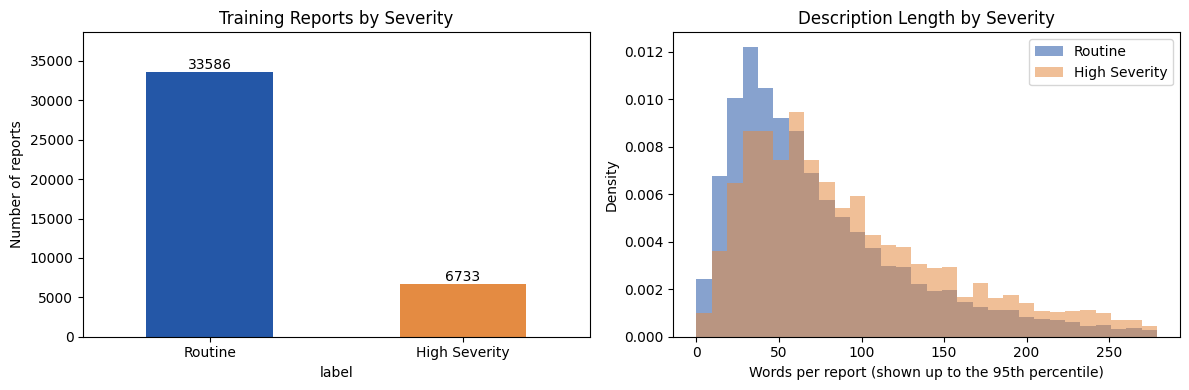

Training class counts:
label
Routine          33586
High Severity     6733
Name: count, dtype: int64

Median words per report:
Severity
High Severity    83.0
Routine          61.0
Name: Word count, dtype: float64


In [5]:
import matplotlib.pyplot as plt

class_order = ["Routine", "High Severity"]
train_counts = y_train.value_counts().reindex(class_order)

eda = pd.DataFrame({
    "Severity": y_train,
    "Word count": X_train.str.split().str.len(),
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

train_counts.plot.bar(ax=axes[0], color=["#2457A7", "#E48B42"], rot=0)
axes[0].bar_label(axes[0].containers[0], fmt="%.0f")
axes[0].set_title("Training Reports by Severity")
axes[0].set_ylabel("Number of reports")
axes[0].set_ylim(0, train_counts.max() * 1.15)

# Limit the plot to the 95th percentile so long logs don't squash it.
word_limit = int(eda["Word count"].quantile(0.95))
for label, color in zip(class_order, ["#2457A7", "#E48B42"]):
    lengths = eda.loc[eda["Severity"].eq(label), "Word count"]
    axes[1].hist(
        lengths, bins=30, range=(0, word_limit),
        density=True, alpha=0.55, label=label, color=color,
    )

axes[1].set_title("Description Length by Severity")
axes[1].set_xlabel("Words per report (shown up to the 95th percentile)")
axes[1].set_ylabel("Density")
axes[1].legend()

fig.tight_layout()
fig.savefig("bug_report_eda.png", dpi=200, bbox_inches="tight")
plt.show()

print("Training class counts:")
print(train_counts)
print("\nMedian words per report:")
print(eda.groupby("Severity")["Word count"].median())

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=20_000,
    ngram_range=(1, 2),
    min_df=3,
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Test matrix:", X_test_tfidf.shape)


Training matrix: (40319, 20000)
Test matrix: (10080, 20000)


In [7]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

nb_predictions = nb_model.predict(X_test_tfidf)

print(f"Naive Bayes accuracy: {accuracy_score(y_test, nb_predictions):.2%}")
print(classification_report(y_test, nb_predictions, digits=3, zero_division=0))

Naive Bayes accuracy: 78.18%
               precision    recall  f1-score   support

High Severity      0.296     0.222     0.254      1683
      Routine      0.852     0.894     0.872      8397

     accuracy                          0.782     10080
    macro avg      0.574     0.558     0.563     10080
 weighted avg      0.759     0.782     0.769     10080



In [8]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

lr_predictions = lr_model.predict(X_test_tfidf)

print(f"Logistic Regression accuracy: {accuracy_score(y_test, lr_predictions):.2%}")
print(classification_report(y_test, lr_predictions, digits=3, zero_division=0))

Logistic Regression accuracy: 83.42%
               precision    recall  f1-score   support

High Severity      0.549     0.040     0.074      1683
      Routine      0.838     0.993     0.909      8397

     accuracy                          0.834     10080
    macro avg      0.693     0.517     0.492     10080
 weighted avg      0.790     0.834     0.770     10080



In [9]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(random_state=42)
svm_model.fit(X_train_tfidf, y_train)

svm_predictions = svm_model.predict(X_test_tfidf)

print(f"Linear SVM accuracy: {accuracy_score(y_test, svm_predictions):.2%}")
print(classification_report(y_test, svm_predictions, digits=3, zero_division=0))

Linear SVM accuracy: 82.62%
               precision    recall  f1-score   support

High Severity      0.443     0.159     0.234      1683
      Routine      0.851     0.960     0.902      8397

     accuracy                          0.826     10080
    macro avg      0.647     0.559     0.568     10080
 weighted avg      0.782     0.826     0.790     10080



In [10]:
from sklearn.metrics import precision_recall_fscore_support

predictions = {
    "Always Routine": ["Routine"] * len(y_test),
    "Naive Bayes": nb_predictions,
    "Logistic Regression": lr_predictions,
    "Linear SVM": svm_predictions,
}

rows = []

for model_name, predicted in predictions.items():
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test,
        predicted,
        average="binary",
        pos_label="High Severity",
        zero_division=0,
    )

    rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predicted),
        "High Severity Precision": precision,
        "High Severity Recall": recall,
        "High Severity F1": f1,
    })

results = pd.DataFrame(rows).set_index("Model")
display(results.style.format("{:.2%}"))

,Accuracy,High Severity Precision,High Severity Recall,High Severity F1
Model,,,,
Always Routine,83.30%,0.00%,0.00%,0.00%
Naive Bayes,78.18%,29.59%,22.22%,25.38%
Logistic Regression,83.42%,54.92%,3.98%,7.42%
Linear SVM,82.62%,44.28%,15.86%,23.36%


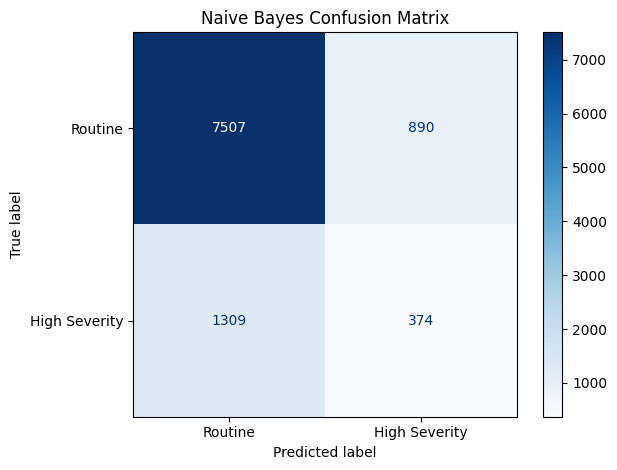

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    nb_predictions,
    labels=["Routine", "High Severity"],
    cmap="Blues",
    values_format="d",
)

plt.title("Naive Bayes Confusion Matrix")
plt.tight_layout()
plt.show()

In [12]:
nb_test_results = pd.DataFrame({
    "Description": X_test,
    "Actual label": y_test,
    "Predicted label": nb_predictions,
})

missed_bugs = nb_test_results[
    (nb_test_results["Actual label"] == "High Severity")
    & (nb_test_results["Predicted label"] == "Routine")
]

example = missed_bugs.iloc[0]

print("Actual label:", example["Actual label"])
print("Predicted label:", example["Predicted label"])
print("\nBug description:")
print(example["Description"][:1500])

Actual label: High Severity
Predicted label: Routine

Bug description:
1) Open the Run dialog (i.e. click on down arrow beside the running man, select "Run..." from pop 
up)
2) Select any item in the "Java Application" category (create one if needed)
3) click on "Arguments" tab.
4) click in "VM Arguments:" text field.
5) type characters.

notice that, the i-beam appears and disappears in the "Configurations:" area once for each 
character that is typed.


In [13]:
def predict_severity(description):
    features = tfidf.transform([description])

    return pd.DataFrame({
        "Model": ["Naive Bayes", "Logistic Regression", "Linear SVM"],
        "Predicted severity": [
            nb_model.predict(features)[0],
            lr_model.predict(features)[0],
            svm_model.predict(features)[0],
        ],
    })

display(predict_severity(example["Description"]))

print("Recorded severity:", example["Actual label"])

,Model,Predicted severity
0,Naive Bayes,Routine
1,Logistic Regression,Routine
2,Linear SVM,Routine


Recorded severity: High Severity


In [14]:
caught_by_any = (
    (nb_predictions == "High Severity")
    | (lr_predictions == "High Severity")
    | (svm_predictions == "High Severity")
)

caught_example = nb_test_results.loc[
    y_test.eq("High Severity") & caught_by_any
].iloc[0]

print(caught_example["Description"][:600])
display(predict_severity(caught_example["Description"]))
print("Recorded severity:", caught_example["Actual label"])

I performed a Replace With Branch or Version after cancelling a previous one 
and got an exception ("Resources could not be deleted"). The dialog did not 
have any details that said what resources could not be deleted. The 
CVSException#wrapException() method copies the info from the core status but 
not the children. It should copy the childen as well.

Exception in modal context operation:
java.lang.reflect.InvocationTargetException: 
org.eclipse.team.internal.ccvs.core.CVSException: Problem deleting resource: 
Problems encountered while deleting resources.
	at org.eclipse.team.internal.ccvs


,Model,Predicted severity
0,Naive Bayes,High Severity
1,Logistic Regression,Routine
2,Linear SVM,Routine


Recorded severity: High Severity


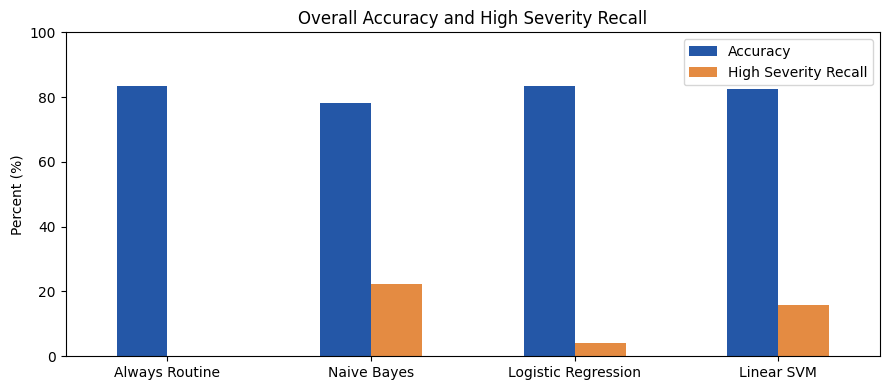

In [15]:
ax = (results[["Accuracy", "High Severity Recall"]] * 100).plot(
    kind="bar",
    figsize=(9, 4),
    rot=0,
    color=["#2457A7", "#E48B42"],
)

ax.set_title("Overall Accuracy and High Severity Recall")
ax.set_ylabel("Percent (%)")
ax.set_xlabel("")
ax.set_ylim(0, 100)
ax.legend(loc="upper right")

plt.tight_layout()
plt.savefig("model_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

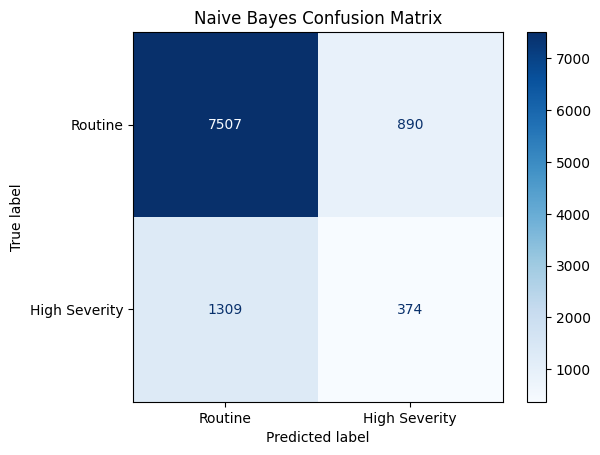

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay
from google.colab import files

matrix = ConfusionMatrixDisplay.from_predictions(
    y_test,
    nb_predictions,
    labels=["Routine", "High Severity"],
    cmap="Blues",
    values_format="d",
)

matrix.ax_.set_title("Naive Bayes Confusion Matrix")

filename = "naive_bayes_confusion_matrix.png"
matrix.figure_.savefig(filename, dpi=200, bbox_inches="tight")
files.download(filename)

In [17]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train,
)

print("Reports for training and cross-validation:", len(X_fit))
print("Reports for threshold selection:", len(X_val))
print("\nValidation class counts:")
print(y_val.value_counts())

Reports for training and cross-validation: 32255
Reports for threshold selection: 8064

Validation class counts:
label
Routine          6717
High Severity    1347
Name: count, dtype: int64


In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, make_scorer
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

severity_f1 = make_scorer(
    f1_score, pos_label="High Severity", zero_division=0
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20_000,
        ngram_range=(1, 2),
        min_df=3,
    )),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000)),
])

lr_search = GridSearchCV(
    lr_pipeline,
    param_grid={"model__C": [0.1, 1, 10]},
    scoring=severity_f1,
    cv=cv,
    n_jobs=1,
    verbose=2,
)

lr_search.fit(X_fit, y_fit)

print("Best C:", lr_search.best_params_["model__C"])
print(f"Best mean CV High Severity F1: {lr_search.best_score_:.2%}")

Fitting 5 folds for each of 3 candidates, totalling 15 fits
[CV] END .......................................model__C=0.1; total time=  14.8s
[CV] END .......................................model__C=0.1; total time=  27.5s
[CV] END .......................................model__C=0.1; total time=  23.7s
[CV] END .......................................model__C=0.1; total time=  20.5s
[CV] END .......................................model__C=0.1; total time=  15.5s
[CV] END .........................................model__C=1; total time=  17.0s
[CV] END .........................................model__C=1; total time=  17.5s
[CV] END .........................................model__C=1; total time=  18.7s
[CV] END .........................................model__C=1; total time=  22.0s
[CV] END .........................................model__C=1; total time=  18.4s
[CV] END ........................................model__C=10; total time=  19.2s
[CV] END ........................................

In [19]:
from sklearn.base import clone
from sklearn.svm import LinearSVC

svm_pipeline = clone(lr_pipeline).set_params(
    model=LinearSVC(
        class_weight="balanced",
        max_iter=5000,
        random_state=42,
    )
)

svm_search = GridSearchCV(
    svm_pipeline,
    param_grid={"model__C": [0.1, 1, 10]},
    scoring=severity_f1,
    cv=cv,
    n_jobs=1,
    verbose=2,
)

svm_search.fit(X_fit, y_fit)

print("Best SVM C:", svm_search.best_params_["model__C"])
print(f"Best mean SVM CV High Severity F1: {svm_search.best_score_:.2%}")

Fitting 5 folds for each of 3 candidates, totalling 15 fits
[CV] END .......................................model__C=0.1; total time=  14.6s
[CV] END .......................................model__C=0.1; total time=  14.5s
[CV] END .......................................model__C=0.1; total time=  14.8s
[CV] END .......................................model__C=0.1; total time=  14.9s
[CV] END .......................................model__C=0.1; total time=  14.9s
[CV] END .........................................model__C=1; total time=  17.5s
[CV] END .........................................model__C=1; total time=  15.5s
[CV] END .........................................model__C=1; total time=  15.2s
[CV] END .........................................model__C=1; total time=  15.8s
[CV] END .........................................model__C=1; total time=  16.5s
[CV] END ........................................model__C=10; total time=  20.5s
[CV] END ........................................

In [20]:
from tempfile import TemporaryDirectory
from sklearn.naive_bayes import ComplementNB, MultinomialNB

nb_grid = {
    "model": [MultinomialNB(), ComplementNB()],
    "model__alpha": [0.1, 0.5, 1.0],
}

# Reuse TF-IDF for candidates evaluated on the same training fold.
with TemporaryDirectory() as cache_dir:
    nb_pipeline = clone(lr_pipeline).set_params(
        model=MultinomialNB(),
        memory=cache_dir,
    )

    nb_search = GridSearchCV(
        nb_pipeline,
        param_grid=nb_grid,
        scoring=severity_f1,
        cv=cv,
        n_jobs=1,
        verbose=2,
    )
    nb_search.fit(X_fit, y_fit)

tuned_nb_model = nb_search.best_estimator_
tuned_nb_model.set_params(memory=None)

nb_cv_results = pd.DataFrame({
    "Variant": [type(model).__name__ for model in nb_search.cv_results_["param_model"]],
    "Alpha": nb_search.cv_results_["param_model__alpha"],
    "Mean CV High Severity F1": nb_search.cv_results_["mean_test_score"],
})

display(nb_cv_results.sort_values("Mean CV High Severity F1", ascending=False))
print("Best Naive Bayes variant:", type(tuned_nb_model.named_steps["model"]).__name__)
print("Best alpha:", nb_search.best_params_["model__alpha"])
print(f"Best mean NB CV High Severity F1: {nb_search.best_score_:.2%}")

Fitting 5 folds for each of 6 candidates, totalling 30 fits
[CV] END ............model=MultinomialNB(), model__alpha=0.1; total time=  14.7s
[CV] END ............model=MultinomialNB(), model__alpha=0.1; total time=  14.6s
[CV] END ............model=MultinomialNB(), model__alpha=0.1; total time=  14.5s
[CV] END ............model=MultinomialNB(), model__alpha=0.1; total time=  15.6s
[CV] END ............model=MultinomialNB(), model__alpha=0.1; total time=  14.5s
[CV] END ............model=MultinomialNB(), model__alpha=0.5; total time=   2.2s
[CV] END ............model=MultinomialNB(), model__alpha=0.5; total time=   2.1s
[CV] END ............model=MultinomialNB(), model__alpha=0.5; total time=   2.1s
[CV] END ............model=MultinomialNB(), model__alpha=0.5; total time=   2.2s
[CV] END ............model=MultinomialNB(), model__alpha=0.5; total time=   3.5s
[CV] END ............model=MultinomialNB(), model__alpha=1.0; total time=   2.2s
[CV] END ............model=MultinomialNB(), model

,Variant,Alpha,Mean CV High Severity F1
3,ComplementNB,0.1,0.337364
4,ComplementNB,0.5,0.316587
5,ComplementNB,1.0,0.291324
0,MultinomialNB,0.1,0.275052
1,MultinomialNB,0.5,0.263166
2,MultinomialNB,1.0,0.248971


Best Naive Bayes variant: ComplementNB
Best alpha: 0.1
Best mean NB CV High Severity F1: 33.74%


In [21]:
import numpy as np
from sklearn.metrics import precision_recall_curve

tuned_models = {
    "Balanced Logistic Regression": lr_search.best_estimator_,
    "Balanced Linear SVM": svm_search.best_estimator_,
    "Complement Naive Bayes": tuned_nb_model,
}

def high_severity_scores(model, descriptions):
    high_index = list(model.classes_).index("High Severity")

    if hasattr(model, "predict_proba"):
        return model.predict_proba(descriptions)[:, high_index]

    # Binary SVM scores point toward classes_[1].
    scores = model.decision_function(descriptions)
    return scores if high_index == 1 else -scores

thresholds = {}
validation_rows = []

for name, model in tuned_models.items():
    scores = high_severity_scores(model, X_val)

    precision, recall, cutoffs = precision_recall_curve(
        y_val.eq("High Severity"), scores
    )

    # The final precision and recall pair has no matching threshold.
    p, r = precision[:-1], recall[:-1]
    f1 = 2 * p * r / np.maximum(p + r, 1e-12)
    best_index = int(np.argmax(f1))

    thresholds[name] = float(cutoffs[best_index])
    validation_rows.append({
        "Model": name,
        "Threshold": thresholds[name],
        "Precision": p[best_index],
        "Recall": r[best_index],
        "F1": f1[best_index],
    })

validation_results = pd.DataFrame(validation_rows).set_index("Model")
display(validation_results.style.format({
    "Threshold": "{:.4f}",
    "Precision": "{:.2%}",
    "Recall": "{:.2%}",
    "F1": "{:.2%}",
}))

,Threshold,Precision,Recall,F1
Model,,,,
Balanced Logistic Regression,0.4929,29.59%,59.09%,39.44%
Balanced Linear SVM,-0.0247,29.38%,60.58%,39.57%
Complement Naive Bayes,0.2900,25.15%,64.22%,36.14%


In [22]:
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    precision_recall_fscore_support,
)

test_is_high = y_test.eq("High Severity")
tuned_test_predictions = {}
tuned_test_scores = {}
test_rows = []

for name, model in tuned_models.items():
    scores = high_severity_scores(model, X_test)
    predicted = np.where(scores >= thresholds[name], "High Severity", "Routine")

    tuned_test_scores[name] = scores
    tuned_test_predictions[name] = predicted

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test,
        predicted,
        average="binary",
        pos_label="High Severity",
        zero_division=0,
    )

    test_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predicted),
        "High Severity Precision": precision,
        "High Severity Recall": recall,
        "High Severity F1": f1,
        "Average Precision": average_precision_score(test_is_high, scores),
    })

tuned_test_results = pd.DataFrame(test_rows).set_index("Model")
tuned_test_results.to_csv("tuned_test_results.csv")
display(tuned_test_results.style.format("{:.2%}"))

,Accuracy,High Severity Precision,High Severity Recall,High Severity F1,Average Precision
Model,,,,,
Balanced Logistic Regression,69.48%,29.75%,60.78%,39.95%,34.46%
Balanced Linear SVM,68.66%,29.21%,61.62%,39.63%,34.40%
Complement Naive Bayes,62.34%,25.32%,64.41%,36.35%,28.34%


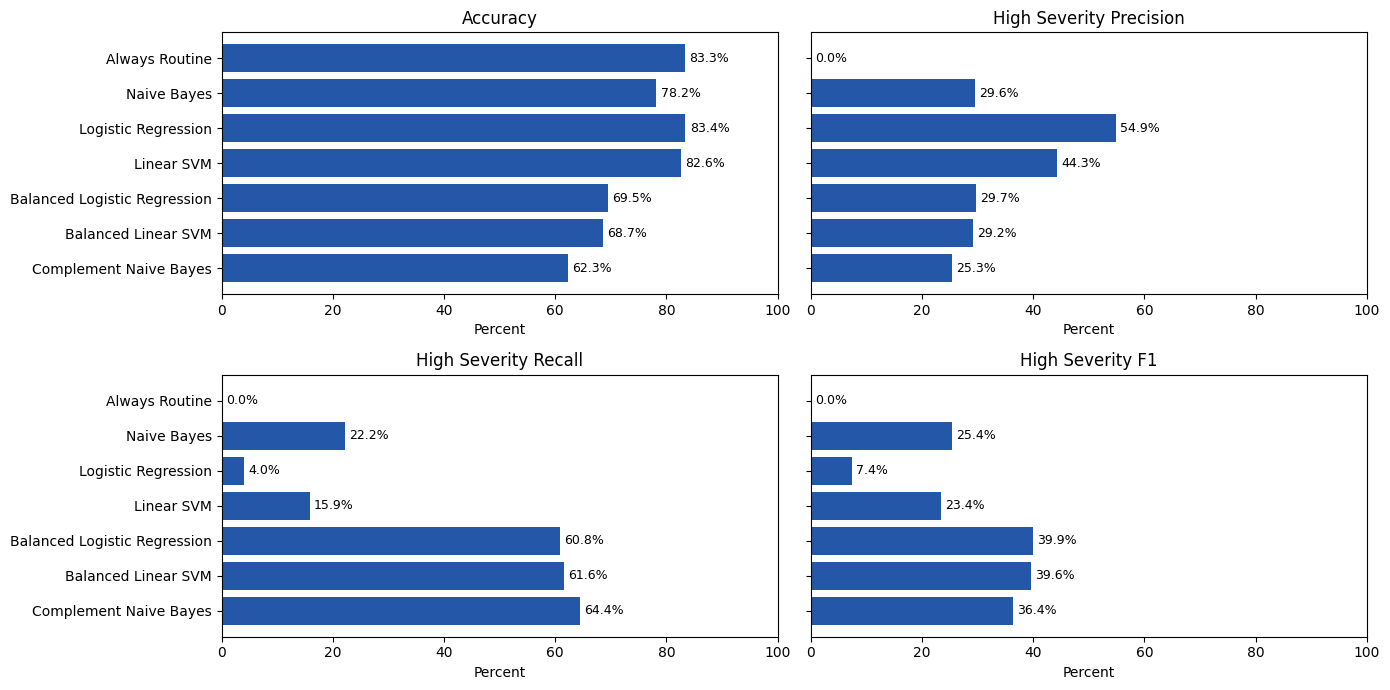

In [23]:
comparison = pd.concat([results, tuned_test_results])
comparison.to_csv("all_model_results.csv")

metrics = [
    "Accuracy",
    "High Severity Precision",
    "High Severity Recall",
    "High Severity F1",
]

fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharey=True)

for ax, metric in zip(axes.flat, metrics):
    bars = ax.barh(comparison.index, comparison[metric] * 100, color="#2457A7")
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
    ax.set_title(metric)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Percent")

axes[0, 0].invert_yaxis()
fig.tight_layout()
fig.savefig("final_model_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

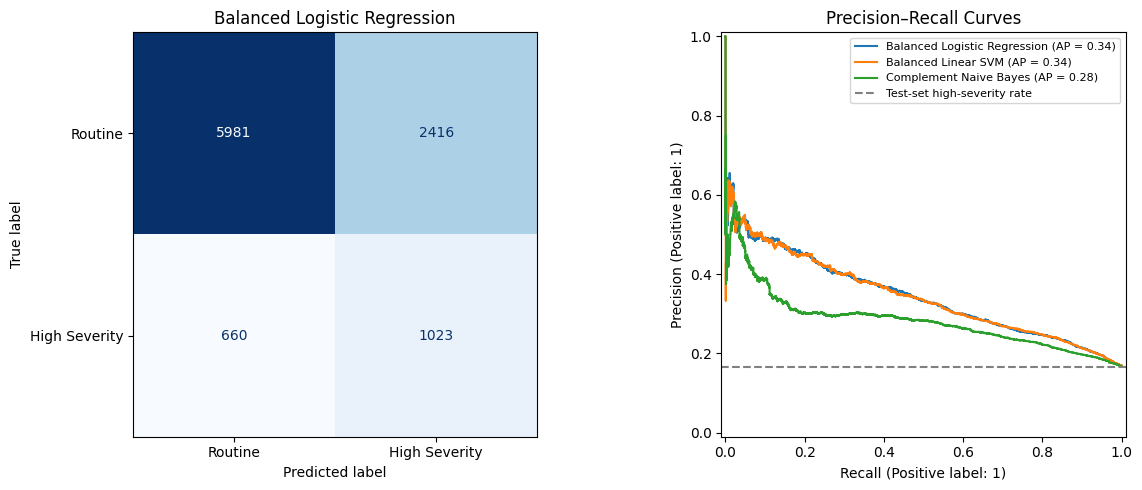

Severe bugs caught: 1023
Severe bugs missed: 660
Routine reports flagged by mistake: 2416


In [24]:
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay

selected_name = "Balanced Logistic Regression"
selected_predictions = tuned_test_predictions[selected_name]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

matrix = ConfusionMatrixDisplay.from_predictions(
    y_test,
    selected_predictions,
    labels=["Routine", "High Severity"],
    cmap="Blues",
    values_format="d",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("Balanced Logistic Regression")

for name, scores in tuned_test_scores.items():
    PrecisionRecallDisplay.from_predictions(
        test_is_high, scores, name=name, ax=axes[1]
    )

axes[1].axhline(
    test_is_high.mean(),
    color="gray",
    linestyle="--",
    label="Test-set high-severity rate",
)
axes[1].set_title("Precision–Recall Curves")
axes[1].legend(loc="upper right", fontsize=8)

fig.tight_layout()
fig.savefig("tuned_model_evaluation.png", dpi=200, bbox_inches="tight")
plt.show()

tn, fp, fn, tp = matrix.confusion_matrix.ravel()
print(f"Severe bugs caught: {tp}")
print(f"Severe bugs missed: {fn}")
print(f"Routine reports flagged by mistake: {fp}")

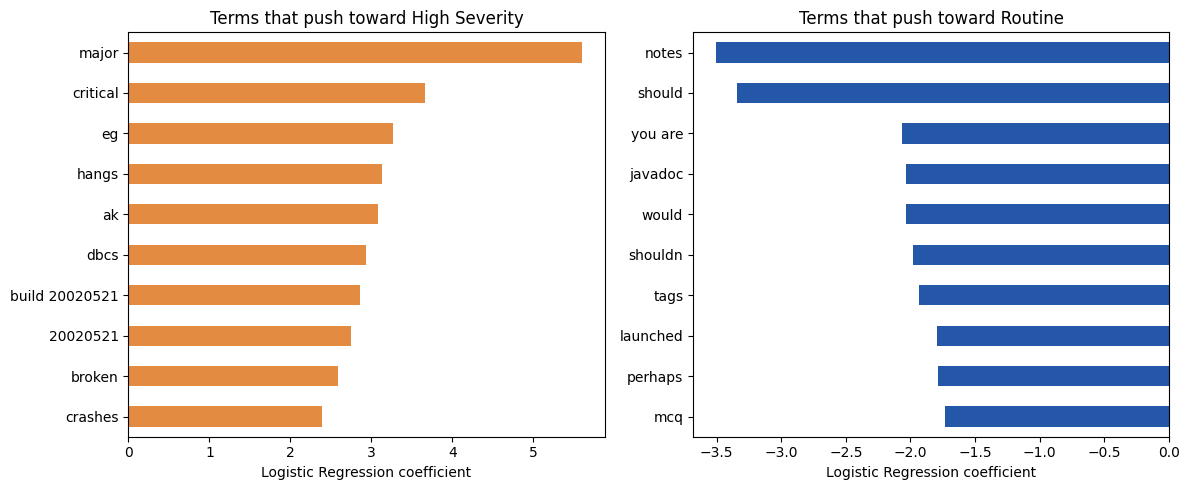

In [25]:
lr_final = lr_search.best_estimator_
vectorizer = lr_final.named_steps["tfidf"]
classifier = lr_final.named_steps["model"]

terms = vectorizer.get_feature_names_out()
weights = classifier.coef_[0]

# Positive coefficients point toward classes_[1].
# Orient them so positive weights point toward High Severity.
if classifier.classes_[1] != "High Severity":
    weights = -weights

term_weights = pd.Series(weights, index=terms)
top_high = term_weights.nlargest(10)
top_routine = term_weights.nsmallest(10)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

top_high.sort_values().plot.barh(ax=axes[0], color="#E48B42")
top_routine.sort_values(ascending=False).plot.barh(ax=axes[1], color="#2457A7")

axes[0].set_title("Terms that push toward High Severity")
axes[1].set_title("Terms that push toward Routine")

for ax in axes:
    ax.set_xlabel("Logistic Regression coefficient")

fig.tight_layout()
fig.savefig("severity_term_weights.png", dpi=200, bbox_inches="tight")
plt.show()

In [26]:
# Keep only the reports actually labeled High Severity.
actual_high = y_test.eq("High Severity").to_numpy()
caught = selected_predictions[actual_high] == "High Severity"

# Resample the high-severity reports 5,000 times with replacement.
rng = np.random.default_rng(42)
bootstrap_recalls = np.array([
    rng.choice(caught, size=len(caught), replace=True).mean()
    for _ in range(5000)
])

lower, upper = np.percentile(bootstrap_recalls, [2.5, 97.5])

print(f"High-severity reports caught: {caught.sum()} of {len(caught)}")
print(f"Test recall: {caught.mean():.2%}")
print(f"95% bootstrap confidence interval: {lower:.2%} to {upper:.2%}")

High-severity reports caught: 1023 of 1683
Test recall: 60.78%
95% bootstrap confidence interval: 58.41% to 63.10%


In [31]:
def predict_tuned_severity(description):
    predictions = []

    for name, model in tuned_models.items():
        score = high_severity_scores(model, [description])[0]
        severity = "High Severity" if score >= thresholds[name] else "Routine"
        predictions.append({"Model": name, "Predicted severity": severity})

    return pd.DataFrame(predictions)


demo_cases = {
    "Original Naive Bayes false negative": example,
    "JVM startup report": caught_example,
}

demo_case = "Original Naive Bayes false negative"
demo_report = demo_cases[demo_case]

print(demo_case)
print(demo_report["Description"][:600])
display(predict_tuned_severity(demo_report["Description"]))

EMF code-generation report
1) Open the Run dialog (i.e. click on down arrow beside the running man, select "Run..." from pop 
up)
2) Select any item in the "Java Application" category (create one if needed)
3) click on "Arguments" tab.
4) click in "VM Arguments:" text field.
5) type characters.

notice that, the i-beam appears and disappears in the "Configurations:" area once for each 
character that is typed.


,Model,Predicted severity
0,Balanced Logistic Regression,Routine
1,Balanced Linear SVM,Routine
2,Complement Naive Bayes,Routine


In [28]:
print("Recorded severity:", demo_report["Actual label"])

Recorded severity: High Severity


In [29]:
from importlib.metadata import version
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

packages = ["numpy", "pandas", "scikit-learn", "matplotlib", "joblib", "ipython"]
Path("requirements.txt").write_text(
    "\n".join(f"{package}=={version(package)}" for package in packages) + "\n",
    encoding="utf-8",
)

Path("README.md").write_text(
    """# Software Bug Severity Prediction

## Run in Google Colab

1. Open Bug_Severity_Prediction.ipynb.
2. Download my_dataset.csv from the Eclipse bug-reports dataset:
   https://huggingface.co/datasets/AndressaStefany/bug-reports
3. Upload the CSV to the Colab Files panel. If needed, update dataset_path
   in the first code cell to match the uploaded file path.
4. Run the notebook from top to bottom. The grid searches take several
   minutes each on CPU.

The notebook uses bug descriptions to compare original and tuned classifiers.
Hyperparameters are chosen by five-fold cross-validation, and classification
thresholds are selected on a separate validation split.

For the demo, change demo_case in the prediction cell and run it. Run the
following cell to reveal the recorded label.

requirements.txt records the package versions used in this Colab session.
""",
    encoding="utf-8",
)

export_files = [
    "README.md",
    "requirements.txt",
    "all_model_results.csv",
    "tuned_test_results.csv",
    "bug_report_eda.png",
    "final_model_comparison.png",
    "tuned_model_evaluation.png",
    "severity_term_weights.png",
]

with ZipFile("bug_severity_outputs.zip", "w", compression=ZIP_DEFLATED) as archive:
    for filename in export_files:
        archive.write(filename)

print("Created bug_severity_outputs.zip")

Created bug_severity_outputs.zip
